# kkkk.ipynb

**目的（Purpose）：**
- 实验性/临时笔记本：记录探索性分析或短期实验，便于复现与回顾。

**输入（Inputs）：**
- 可能引用项目中任意数据源（请在顶部列出并确认路径）。

**输出（Outputs）：**
- 实验结果示例、绘图或临时文件，通常用于验证假设或方法效果。

**依赖（Dependencies）：**
- 根据实验内容而定。建议顶部明确列出所需包并提供安装命令。

安装示例：
```bash
pip install geopandas rasterio numpy matplotlib
```

**运行提示（How to run）：**
- 作为实验笔记本，逐单元运行并在关键点保存结果；建议在单独环境中运行以免污染主环境。

**备注（Notes）：**
- 若实验具有随机性，请设置随机种子并记录环境信息（Python 版本与库版本）。

In [ ]:
import rasterio
from rasterio.enums import Resampling
from rasterio.warp import reproject, Resampling as WarpResampling
import numpy as np
import os

def reproject_and_resample(src_path, ref_crs, ref_transform, ref_width, ref_height):
    with rasterio.open(src_path) as src:
        dst_array = np.empty((ref_height, ref_width), dtype=np.float32)

        reproject(
            source=rasterio.band(src, 1),
            destination=dst_array,
            src_transform=src.transform,
            src_crs=src.crs,
            dst_transform=ref_transform,
            dst_crs=ref_crs,
            resampling=WarpResampling.nearest
        )

        return dst_array

def resample_and_merge_single_band(base_raster, layers_dict, output_path):
    with rasterio.open(base_raster) as ref:
        ref_meta = ref.meta.copy()
        ref_height, ref_width = ref.height, ref.width
        ref_transform = ref.transform
        # 强制改成 EPSG:32651
        ref_crs = rasterio.crs.CRS.from_epsg(32651)

    dtype = np.int32
    nodata_val = 0
    merged_array = np.full((ref_height, ref_width), nodata_val, dtype=dtype)

    def write_layer(input_array, assign_value, overwrite=True):
        arr = input_array.astype(np.float32)
        valid_mask = (~np.isnan(arr)) & (arr != 0) & (arr != 255)

        if overwrite:
            merged_array[valid_mask] = assign_value if isinstance(assign_value, (int, float)) else arr[valid_mask]
        else:
            write_mask = valid_mask & (merged_array == 0)
            merged_array[write_mask] = assign_value if isinstance(assign_value, (int, float)) else arr[write_mask]

    # 按优先级从低到高写入，后面覆盖前面
    if "water" in layers_dict and os.path.exists(layers_dict["water"]):
        water = reproject_and_resample(layers_dict["water"], ref_crs, ref_transform, ref_width, ref_height)
        write_layer(water, 2000,  overwrite=True)

    if "park" in layers_dict and os.path.exists(layers_dict["park"]):
        park = reproject_and_resample(layers_dict["park"], ref_crs, ref_transform, ref_width, ref_height)
        write_layer(park, 3000,  overwrite=True)

    if "street" in layers_dict and os.path.exists(layers_dict["street"]):
        street = reproject_and_resample(layers_dict["street"], ref_crs, ref_transform, ref_width, ref_height)
        write_layer(street, 4000, overwrite=True)

    if "building" in layers_dict and os.path.exists(layers_dict["building"]):
        building = reproject_and_resample(layers_dict["building"], ref_crs, ref_transform, ref_width, ref_height)
        write_layer(building, building,  overwrite=True)

    # 元数据更新和写出同你代码
    out_meta = ref_meta.copy()
    out_meta.update({
        "count": 1,
        "dtype": "float32",
        "height": ref_height,
        "width": ref_width,
        "transform": ref_transform,
        "crs": ref_crs,
        "nodata": np.nan
    })

    with rasterio.open(output_path, "w", **out_meta) as dst:
        dst.write(merged_array, 1)
        print(f"✅ 合成单波段栅格保存至: {output_path}")

# 示例调用：
n = 7404
base_raster = rf"D:\shanghai workshop\raster\final_street_tiles\tile_{n}.tif"
layers = {
    "building": rf"D:\shanghai workshop\raster\final_building_tiles\building_tile_{n}.tif",
    "park": rf"D:\shanghai workshop\raster\final_park_tiles\park_tile_{n}.tif",
    "water": rf"D:\shanghai workshop\raster\final_water_tiles\water_tile_{n}.tif",
    "street": rf"D:\shanghai workshop\raster\final_street_tiles\tile_{n}.tif"
}

output_path = rf"D:\shanghai workshop\raster\merged\merged_tile_{n}.tif"
resample_and_merge_single_band(base_raster, layers, output_path)


### 单元说明：将矢量要素的多个字段栅格化为多波段 GeoTIFF

目的：对 `shapefile_path` 中指定的多个属性字段分别栅格化，并将结果堆叠为多波段 GeoTIFF（每个网格单独输出一个文件）。

关键点：
- 函数：`rasterize_multiple_fields_to_multiband(shapefile_path, grid_path, class_fields, output_dir, ...)`。
- 行为：为字符型字段自动创建映射（类别→整数），并在每个网格范围内分别 rasterize；每个字段对应一个波段，最终写出 `building_tile_{ID}.tif`。
- 主要参数：`resolution`（像素大小）、`nodata`（无数据值）、`start_id`（跳过小于该 ID 的网格）。
- 注意：确保 `class_fields` 在 shapefile 中存在；如果字段是字符串型，映射会从 1 开始，0 为背景。

In [2]:
import geopandas as gpd
import rasterio
from rasterio.features import rasterize
from rasterio.transform import from_origin
import os
import numpy as np

def rasterize_multiple_fields_to_multiband(shapefile_path, grid_path, class_fields, output_dir, resolution=10, nodata=255, start_id=0):
    gdf = gpd.read_file(shapefile_path)
    grid = gpd.read_file(grid_path)

    if not gdf.crs.is_projected:
        gdf = gdf.to_crs(epsg=32651)
    if not grid.crs.is_projected:
        grid = grid.to_crs(epsg=32651)
    if gdf.crs != grid.crs:
        grid = grid.to_crs(gdf.crs)

    gdf = gdf[~gdf.geometry.is_empty & gdf.geometry.notnull()]
    grid = grid[~grid.geometry.is_empty & grid.geometry.notnull()]

    os.makedirs(output_dir, exist_ok=True)

    # ✅ 第一步：提前为所有字段生成全局映射字典
    field_maps = {}
    for field in class_fields:
        if field not in gdf.columns:
            raise ValueError(f"字段 {field} 不存在于 shapefile 中")
        if gdf[field].dtype.kind in ['O', 'U']:  # 字符型
            unique_vals = sorted(gdf[field].dropna().unique())
            val_map = {v: i+1 for i, v in enumerate(unique_vals)}
            print(f"字段 {field} 的映射：{val_map}")
            field_maps[field] = val_map
            gdf[f"__mapped_{field}"] = gdf[field].map(val_map).fillna(0).astype(int)
        else:
            gdf[f"__mapped_{field}"] = gdf[field].fillna(0)

    for idx, cell in grid.iterrows():
        tile_id = cell["ID"]

        # ✅ 跳过起始 ID 之前的 tile
        if tile_id < start_id:
            continue

        out_path = os.path.join(output_dir, f"building_tile_{tile_id}.tif")

        if os.path.exists(out_path):
            print(f"⏩ 已存在，跳过: {out_path}")
            continue

        grid_geom = cell.geometry
        clipped = gpd.overlay(gdf, gpd.GeoDataFrame(geometry=[grid_geom], crs=gdf.crs), how="intersection")
        if clipped.empty:
            continue

        minx, miny, maxx, maxy = grid_geom.bounds
        width = int((maxx - minx) / resolution)
        height = int((maxy - miny) / resolution)
        transform = from_origin(minx, maxy, resolution, resolution)

        bands = []

        for field in class_fields:
            mapped_col = f"__mapped_{field}"
            class_vals = clipped[mapped_col]
            shapes = [(geom, val) for geom, val in zip(clipped.geometry, class_vals)]

            raster = rasterize(
                shapes=shapes,
                out_shape=(height, width),
                transform=transform,
                fill=nodata,
                dtype='uint8' if class_vals.dtype == int else 'float32'
            )
            bands.append(raster)

        bands_array = np.stack(bands, axis=0)

        with rasterio.open(
            out_path,
            "w",
            driver="GTiff",
            height=height,
            width=width,
            count=len(class_fields),
            dtype=bands_array.dtype,
            crs=gdf.crs,
            transform=transform,
            nodata=nodata
        ) as dst:
            dst.write(bands_array)

        print(f"✅ 输出: {out_path}")

rasterize_multiple_fields_to_multiband(
    shapefile_path=r'D:\shanghai workshop\vector\Building_processed nearest 1 to 500m_finver\result\building_UTM51N.shp',
    grid_path=r"D:\shanghai workshop\vector\shanghai_grid_256m_clipped.shp",
    class_fields=["Height", "Function", "Style"],
    output_dir=r"D:\shanghai workshop\raster\final_building_tiles_with_bands",
    resolution=1,
    nodata=255,
    start_id=90000
)

字段 Function 的映射：{'Business': 1, 'Industry': 2, 'Office': 3, 'Other': 4, 'Public service': 5, 'Residence': 6}
字段 Style 的映射：{'M': 1, 'Modern': 2, 'Postmodern': 3, 'Traditional': 4}


KeyboardInterrupt: 

### 单元说明：重投影/重采样并合并多源图层为多波段 GeoTIFF

目的：以 `base_raster` 为参考，将多源图层（如 building_height, park, water, lst 等）重投影并重采样到统一网格，然后按固定波段顺序合并写出多波段 GeoTIFF。

关键点：
- 包含函数：`reproject_and_resample_band(src_path, band_idx, ...)`（读取指定波段并重采样到参考尺寸）和 `resample_and_merge_multiband(base_raster, layers_dict, output_path)`（构建多波段数组并写出）。
- 波段映射：对于 `building_*` 前缀的图层，映射到不同波段索引；其他图层使用波段 1。
- 输入：`base_raster`（参考栅格）、`layers_dict`（图层路径字典）、`output_path`（输出文件）。
- 输出：多波段 GeoTIFF，`nodata` 使用 `NaN`，波段顺序由 `layer_order` 决定。
- 注意：若某图层缺失或重采样失败，会以 NaN 填充该波段；建议在批量运行前检查 `layers_dict` 的路径有效性。

In [4]:
import geopandas as gpd
import os
import rasterio
from rasterio.enums import Resampling
from rasterio.warp import reproject, calculate_default_transform, Resampling as WarpResampling
import numpy as np
import os

def reproject_and_resample_band(src_path, band_idx, ref_crs, ref_transform, ref_width, ref_height):
    try:
        with rasterio.open(src_path) as src:
            dst_array = np.empty((ref_height, ref_width), dtype=np.float32)

            reproject(
                source=rasterio.band(src, band_idx),
                destination=dst_array,
                src_transform=src.transform,
                src_crs=src.crs,
                dst_transform=ref_transform,
                dst_crs=ref_crs,
                resampling=WarpResampling.nearest
            )
            return dst_array
    except Exception as e:
        print(f"❌ 无法读取或重采样 {src_path} 第 {band_idx} 波段：{e}")
        return None

def resample_and_merge_multiband(base_raster, layers_dict, output_path):
    with rasterio.open(base_raster) as ref:
        src_crs = ref.crs
        dst_crs = rasterio.crs.CRS.from_epsg(32651)

        dst_transform, dst_width, dst_height = calculate_default_transform(
            src_crs, dst_crs, ref.width, ref.height, *ref.bounds
        )

        ref_meta = ref.meta.copy()

    dtype = np.float32
    nodata_val = np.nan
    layer_order = [
        "water",
        "park",
        "street",
        "building_height",  # 替代 building
        "building_type",
        "building_style",
        "landuse",
        "lst"
    ]
    band_count = len(layer_order)

    # 初始化为 NaN
    merged_array = np.full((band_count, dst_height, dst_width), nodata_val, dtype=dtype)

    for i, layer in enumerate(layer_order):
        path = layers_dict.get(layer)

        # building_ 开头的我们就对应不同的 band
        if layer.startswith("building_"):
            band_map = {
                "building_height": 1,
                "building_type": 2,
                "building_style": 3
            }
            band_index = band_map.get(layer, 1)
        else:
            band_index = 1

        if path and os.path.exists(path):
            print(f"📥 正在处理图层 {layer}: {path} (band {band_index})")
            arr = reproject_and_resample_band(path, band_index, dst_crs, dst_transform, dst_width, dst_height)

            if arr is not None:
                valid_mask = (~np.isnan(arr)) & (arr != 0) & (arr != 255)
                cleaned = np.full_like(arr, nodata_val)
                cleaned[valid_mask] = arr[valid_mask]
                merged_array[i] = cleaned
            else:
                print(f"⚠️ 图层 {layer} 重采样失败，保留为 NaN")
        else:
            print(f"⚠️ 图层 {layer} 缺失或路径无效：{path}")


    out_meta = ref_meta.copy()
    out_meta.update({
        "count": band_count,
        "dtype": "float32",
        "height": dst_height,
        "width": dst_width,
        "transform": dst_transform,
        "crs": dst_crs,
        "nodata": nodata_val
    })

    os.makedirs(os.path.dirname(output_path), exist_ok=True)
    with rasterio.open(output_path, "w", **out_meta) as dst:
        dst.write(merged_array)
        print(f"✅ 多波段 GeoTIFF 已保存: {output_path}")

# 示例调用
n = 51738
base_raster = rf"D:\shanghai workshop\raster\visual\street_merge\tile_{n}.tif"
layers = {
    "building_height": rf"D:\shanghai workshop\raster\visual\building_merge\building_tile_{n}.tif",
    "building_type": rf"D:\shanghai workshop\raster\visual\building_merge\building_tile_{n}.tif",
    "building_style": rf"D:\shanghai workshop\raster\visual\building_merge\building_tile_{n}.tif",
    "park": rf"D:\shanghai workshop\raster\visual\park_merge\park_tile_{n}.tif",
    "water": rf"D:\shanghai workshop\raster\visual\water_merge\water_tile_{n}.tif",
    "street": rf"D:\shanghai workshop\raster\visual\street_merge\tile_{n}.tif",
    "landuse": rf"D:\shanghai workshop\raster\visual\landuse_tiles\landuse_tile_{n}.tif",
    "lst": rf"D:\shanghai workshop\raster\visual\lst_merge\lst_tile_{n}.tif"
}
output_path = rf"D:\shanghai workshop\raster\visual\merged_tile_{n}.tif"
resample_and_merge_multiband(base_raster, layers, output_path)
path = r"D:\shanghai workshop\vector\visual.shp"
gdf = gpd.read_file(path)

print(gdf.columns)

id_list = gdf['ID'].tolist()
print(id_list)

for n in id_list:
    base_raster = rf"D:\shanghai workshop\raster\visual\lst_merge\lst_tile_{n}.tif"
    layers = {
        "building_height": rf"D:\shanghai workshop\raster\visual\building_merge\building_tile_{n}.tif",
        "building_type": rf"D:\shanghai workshop\raster\visual\building_merge\building_tile_{n}.tif",
        "building_style": rf"D:\shanghai workshop\raster\visual\building_merge\building_tile_{n}.tif",
        "park": rf"D:\shanghai workshop\raster\visual\park_merge\park_tile_{n}.tif",
        "water": rf"D:\shanghai workshop\raster\visual\water_merge\water_tile_{n}.tif",
        "street": rf"D:\shanghai workshop\raster\visual\street_merge\tile_{n}.tif",
        "landuse": rf"D:\shanghai workshop\raster\visual\landuse_tiles\landuse_tile_{n}.tif",
        "lst": rf"D:\shanghai workshop\raster\visual\lst_merge\lst_tile_{n}.tif"
    }
    output_path = rf"D:\shanghai workshop\raster\visual\merge\merged_tile_{n}.tif"

    if os.path.exists(base_raster):
        try:
            resample_and_merge_multiband(base_raster, layers, output_path)
        except Exception as e:
            print(f"❌ 处理 tile_{n} 时出错: {e}")
    else:
        print(f"⚠️ 缺失 base_raster: tile_{n}，跳过该tile")


⚠️ 图层 water 缺失或路径无效：D:\shanghai workshop\raster\visual\water_merge\water_tile_51738.tif
⚠️ 图层 park 缺失或路径无效：D:\shanghai workshop\raster\visual\park_merge\park_tile_51738.tif
📥 正在处理图层 street: D:\shanghai workshop\raster\visual\street_merge\tile_51738.tif (band 1)
📥 正在处理图层 building_height: D:\shanghai workshop\raster\visual\building_merge\building_tile_51738.tif (band 1)
📥 正在处理图层 building_type: D:\shanghai workshop\raster\visual\building_merge\building_tile_51738.tif (band 2)
📥 正在处理图层 building_style: D:\shanghai workshop\raster\visual\building_merge\building_tile_51738.tif (band 3)
📥 正在处理图层 landuse: D:\shanghai workshop\raster\visual\landuse_tiles\landuse_tile_51738.tif (band 1)
📥 正在处理图层 lst: D:\shanghai workshop\raster\visual\lst_merge\lst_tile_51738.tif (band 1)
✅ 多波段 GeoTIFF 已保存: D:\shanghai workshop\raster\visual\merged_tile_51738.tif
Index(['ID', 'FID_1', 'geometry'], dtype='object')
[51737, 51738, 51739, 51740, 51741, 51742, 51743, 51744, 51745, 51746, 51747, 51748, 51749, 51750, 51

### 单元说明：读取网格并为每个 ID 执行合并/裁剪流程

目的：读取网格 Shapefile（`shanghai_grid_256m_clipped.shp`），确保 CRS 与栅格一致，然后为每个 `ID` 处理对应的合并栅格（例如调用合并函数或后续裁剪）。

关键点：
- 本单元演示如何遍历 `id_list` 并为每个 tile 构造 `layers` 字典与 `output_path`，随后调用 `resample_and_merge_multiband` 生成 `merged_tile_{n}.tif`。
- 也会检查 `base_raster` 是否存在以避免错误。
- 注意：确保 `gdf['ID']` 包含所需的 Tile ID 且路径模板中的文件存在。

In [5]:
import os
import geopandas as gpd
import rasterio
from rasterio.mask import mask

# 读取矢量网格
vector_path = r"D:\shanghai workshop\vector\shanghai_grid_256m_clipped.shp"
gdf = gpd.read_file(vector_path)

# 确保 CRS 和栅格一致（即 EPSG:32651）
gdf = gdf.to_crs(epsg=32651)

# 获取所有 ID 列表
id_list = gdf['ID'].tolist()

# 遍历每个 ID，裁剪同名栅格
for n in id_list:
    input_raster = rf"D:\shanghai workshop\raster\visual\merge\merged_tile_{n}.tif"
    output_raster = rf"D:\shanghai workshop\raster\visual\merge_final\merged_clean_tile_{n}.tif"

    if not os.path.exists(input_raster):
        print(f"⚠️ 跳过缺失文件: merged_tile_{n}.tif")
        continue

    try:
        # 提取该 ID 对应的 polygon
        polygon = gdf[gdf['ID'] == n].geometry.values[0]
        geojson_geom = [polygon.__geo_interface__]

        # 打开栅格并裁剪
        with rasterio.open(input_raster) as src:
            out_image, out_transform = mask(src, geojson_geom, crop=True, nodata=np.nan)
            out_meta = src.meta.copy()

        # 更新元信息
        out_meta.update({
            "height": out_image.shape[1],
            "width": out_image.shape[2],
            "transform": out_transform,
            "nodata": np.nan
        })

        # 写出裁剪后的文件
        os.makedirs(os.path.dirname(output_raster), exist_ok=True)
        with rasterio.open(output_raster, "w", **out_meta) as dest:
            dest.write(out_image)
            print(f"✅ 裁剪完成: clipped_tile_{n}.tif")

    except Exception as e:
        print(f"❌ 裁剪 tile_{n} 出错: {e}")

⚠️ 跳过缺失文件: merged_tile_192.tif
⚠️ 跳过缺失文件: merged_tile_193.tif
⚠️ 跳过缺失文件: merged_tile_194.tif
⚠️ 跳过缺失文件: merged_tile_195.tif
⚠️ 跳过缺失文件: merged_tile_196.tif
⚠️ 跳过缺失文件: merged_tile_532.tif
⚠️ 跳过缺失文件: merged_tile_533.tif
⚠️ 跳过缺失文件: merged_tile_534.tif
⚠️ 跳过缺失文件: merged_tile_535.tif
⚠️ 跳过缺失文件: merged_tile_536.tif
⚠️ 跳过缺失文件: merged_tile_537.tif
⚠️ 跳过缺失文件: merged_tile_538.tif
⚠️ 跳过缺失文件: merged_tile_539.tif
⚠️ 跳过缺失文件: merged_tile_567.tif
⚠️ 跳过缺失文件: merged_tile_568.tif
⚠️ 跳过缺失文件: merged_tile_569.tif
⚠️ 跳过缺失文件: merged_tile_570.tif
⚠️ 跳过缺失文件: merged_tile_571.tif
⚠️ 跳过缺失文件: merged_tile_572.tif
⚠️ 跳过缺失文件: merged_tile_573.tif
⚠️ 跳过缺失文件: merged_tile_574.tif
⚠️ 跳过缺失文件: merged_tile_575.tif
⚠️ 跳过缺失文件: merged_tile_874.tif
⚠️ 跳过缺失文件: merged_tile_875.tif
⚠️ 跳过缺失文件: merged_tile_876.tif
⚠️ 跳过缺失文件: merged_tile_877.tif
⚠️ 跳过缺失文件: merged_tile_878.tif
⚠️ 跳过缺失文件: merged_tile_879.tif
⚠️ 跳过缺失文件: merged_tile_880.tif
⚠️ 跳过缺失文件: merged_tile_881.tif
⚠️ 跳过缺失文件: merged_tile_882.tif
⚠️ 跳过缺失文件: merged_tile_883.tif
⚠️ 跳过缺失文

### 单元说明：按网格裁剪合并后的栅格并保存清理后的切片

目的：遍历网格 `id_list`，对每个 `merged_tile_{n}.tif` 按对应网格多边形裁剪并将裁剪结果保存为 `merged_clean_tile_{n}.tif`。

关键点：
- 输入路径示例：`D:\shanghai workshop\raster\visual\merge\merged_tile_{n}.tif`。
- 裁剪使用：`rasterio.mask.mask`，`nodata` 设置为 `np.nan`，如果输入文件缺失会跳过并打印警告。
- 输出：保存在 `merge_final` 目录下，建议在运行前确认输出目录存在或有写权限。
- 注意：裁剪过程中可能出现异常（如几何与栅格重叠问题），代码会捕获异常并继续处理下一个 tile。

In [7]:
import os
import shutil
import geopandas as gpd

# 路径设置
merge_folder = r"D:\shanghai workshop\raster\visual\merge_final"
case_shapefile = r"D:\shanghai workshop\vector\case.shp"
output_folder = os.path.join(merge_folder, "merge_final_case")

# 创建输出文件夹
os.makedirs(output_folder, exist_ok=True)

# 读取 shapefile 的 ID 字段
gdf = gpd.read_file(case_shapefile)
case_ids = set(map(str, gdf['ID'].tolist()))  # 转成字符串集合，便于匹配

# 遍历 merge_final 文件夹
for filename in os.listdir(merge_folder):
    if filename.startswith("merged_clean_tile_") and filename.endswith(".tif"):
        # 提取 ID
        tile_id = filename.replace("merged_clean_tile_", "").replace(".tif", "")
        if tile_id in case_ids:
            src_path = os.path.join(merge_folder, filename)
            dst_path = os.path.join(output_folder, filename)
            shutil.copy2(src_path, dst_path)
            print(f"✅ 已复制: {filename}")


✅ 已复制: merged_clean_tile_54143.tif
✅ 已复制: merged_clean_tile_54144.tif
✅ 已复制: merged_clean_tile_54145.tif
✅ 已复制: merged_clean_tile_54146.tif
✅ 已复制: merged_clean_tile_54147.tif
✅ 已复制: merged_clean_tile_54486.tif
✅ 已复制: merged_clean_tile_54487.tif
✅ 已复制: merged_clean_tile_54488.tif
✅ 已复制: merged_clean_tile_54489.tif
✅ 已复制: merged_clean_tile_54490.tif
✅ 已复制: merged_clean_tile_54829.tif
✅ 已复制: merged_clean_tile_54830.tif
✅ 已复制: merged_clean_tile_54831.tif
✅ 已复制: merged_clean_tile_54832.tif
✅ 已复制: merged_clean_tile_54833.tif
✅ 已复制: merged_clean_tile_55172.tif
✅ 已复制: merged_clean_tile_55173.tif
✅ 已复制: merged_clean_tile_55174.tif
✅ 已复制: merged_clean_tile_55175.tif
✅ 已复制: merged_clean_tile_55176.tif
✅ 已复制: merged_clean_tile_55515.tif
✅ 已复制: merged_clean_tile_55516.tif
✅ 已复制: merged_clean_tile_55517.tif
✅ 已复制: merged_clean_tile_55518.tif
✅ 已复制: merged_clean_tile_55519.tif


### 单元说明：将多波段栅格按波段转换为 GeoJSON（像素值转要素）

目的：遍历输入文件夹中的每个 `.tif`，对每个波段使用 `rasterio.features.shapes` 将像元值转换为矢量要素，并保存为单独的 GeoJSON（可设置目标 CRS）。

关键点：
- 函数：`raster_to_geojson_per_band(input_folder, output_folder, target_epsg=4326)`。
- 输出命名：每个 TIFF 生成若干 `*_bandname.geojson` 文件，基于 `band_names` 列表命名波段。
- 注意：输出体积可能较大，建议先过滤无效像素或对小面进行面积阈值过滤；转换后会将 CRS 投影到 `target_epsg`。

In [8]:
import os
import rasterio
from rasterio.features import shapes
import numpy as np
import geopandas as gpd
from shapely.geometry import shape

def raster_to_geojson_per_band(input_folder, output_folder, target_epsg=4326):
    os.makedirs(output_folder, exist_ok=True)

    band_names = [
        "water",           # Band 1
        "park",            # Band 2
        "street",          # Band 3
        "building_height", # Band 4
        "building_type",   # Band 5
        "building_style",  # Band 6
        "landuse",         # Band 7
        "lst"              # Band 8
    ]

    for filename in os.listdir(input_folder):
        if filename.lower().endswith(".tif"):
            tif_path = os.path.join(input_folder, filename)

            print(f"📍 正在处理: {tif_path}")

            with rasterio.open(tif_path) as src:
                for i, band_name in enumerate(band_names, start=1):
                    image = src.read(i)
                    mask = (image != src.nodata) & (~np.isnan(image))

                    results = (
                        {"properties": {"value": v}, "geometry": s}
                        for s, v in shapes(image, mask=mask, transform=src.transform)
                    )

                    geoms = list(results)
                    if not geoms:
                        print(f"⚠️ {band_name} 无有效数据，跳过: {filename}")
                        continue

                    gdf = gpd.GeoDataFrame.from_features(geoms, crs=src.crs)
                    gdf = gdf.to_crs(epsg=target_epsg)

                    base_name = filename.replace(".tif", f"_{band_name}.geojson")
                    geojson_path = os.path.join(output_folder, base_name)
                    gdf.to_file(geojson_path, driver="GeoJSON")
                    print(f"✅ {band_name} 已保存为 GeoJSON: {geojson_path}")

# 使用示例
raster_to_geojson_per_band(
    input_folder=r"D:\shanghai workshop\raster\visual\merge_final\merge_final_case",
    output_folder=r"D:\shanghai workshop\raster\visual\merge_final\merge_final_case\geojson_output",
    target_epsg=4326
)

📍 正在处理: D:\shanghai workshop\raster\visual\merge_final\merge_final_case\merged_clean_tile_54143.tif
⚠️ water 无有效数据，跳过: merged_clean_tile_54143.tif
⚠️ park 无有效数据，跳过: merged_clean_tile_54143.tif
✅ street 已保存为 GeoJSON: D:\shanghai workshop\raster\visual\merge_final\merge_final_case\geojson_output\merged_clean_tile_54143_street.geojson
✅ building_height 已保存为 GeoJSON: D:\shanghai workshop\raster\visual\merge_final\merge_final_case\geojson_output\merged_clean_tile_54143_building_height.geojson
✅ building_type 已保存为 GeoJSON: D:\shanghai workshop\raster\visual\merge_final\merge_final_case\geojson_output\merged_clean_tile_54143_building_type.geojson
✅ building_style 已保存为 GeoJSON: D:\shanghai workshop\raster\visual\merge_final\merge_final_case\geojson_output\merged_clean_tile_54143_building_style.geojson
✅ landuse 已保存为 GeoJSON: D:\shanghai workshop\raster\visual\merge_final\merge_final_case\geojson_output\merged_clean_tile_54143_landuse.geojson
✅ lst 已保存为 GeoJSON: D:\shanghai workshop\raster\visu

### 单元说明：根据案例 Shapefile 筛选并复制裁剪后的栅格到 `merge_final_case`

目的：读取 `case.shp` 中的 ID 列，遍历 `merge_final` 目录并将与这些 ID 匹配的 `merged_clean_tile_{ID}.tif` 复制到 `merge_final_case` 子目录，便于对案例集集中处理。

关键点：
- 输入：`case_shapefile`（包含要保留的 ID 列），`merge_folder`（保存 `merged_clean_tile_*.tif` 的文件夹）。
- 操作：使用 `shutil.copy2` 进行文件复制，保留元数据。复制前会创建输出目录。
- 注意：`case_ids` 在代码中以字符串集合方式构造，确保 `ID` 在 shapefile 中的类型与文件名提取方式一致。

In [10]:
import os
import geopandas as gpd
from collections import defaultdict

input_folder = r'D:\shanghai workshop\raster\visual\merge_final\merge_final_case\geojson_output'
output_folder = os.path.join(input_folder, 'merged_by_type')
os.makedirs(output_folder, exist_ok=True)

# 按照类型（如 building_height）分组
layer_groups = defaultdict(list)

for filename in os.listdir(input_folder):
    if filename.endswith('.geojson'):
        # 提取类型部分，如：merged_clean_tile_51738_building_height.geojson
        parts = filename.replace('.geojson', '').split('_')
        if len(parts) >= 2:
            layer_type = parts[-1]  # 取最后一段作为类型
            layer_groups[layer_type].append(os.path.join(input_folder, filename))

# 遍历每组进行合并
for layer_type, file_list in layer_groups.items():
    merged_gdf = gpd.GeoDataFrame()

    for file_path in file_list:
        print(f"📥 读取: {file_path}")
        gdf = gpd.read_file(file_path)
        merged_gdf = gpd.pd.concat([merged_gdf, gdf], ignore_index=True)

    output_path = os.path.join(output_folder, f'merged_{layer_type}.geojson')
    merged_gdf.to_file(output_path, driver='GeoJSON')
    print(f"✅ 已保存合并文件: {output_path}")


📥 读取: D:\shanghai workshop\raster\visual\merge_final\merge_final_case\geojson_output\merged_clean_tile_54143_building_height.geojson
📥 读取: D:\shanghai workshop\raster\visual\merge_final\merge_final_case\geojson_output\merged_clean_tile_54144_building_height.geojson
📥 读取: D:\shanghai workshop\raster\visual\merge_final\merge_final_case\geojson_output\merged_clean_tile_54145_building_height.geojson
📥 读取: D:\shanghai workshop\raster\visual\merge_final\merge_final_case\geojson_output\merged_clean_tile_54146_building_height.geojson
📥 读取: D:\shanghai workshop\raster\visual\merge_final\merge_final_case\geojson_output\merged_clean_tile_54147_building_height.geojson
📥 读取: D:\shanghai workshop\raster\visual\merge_final\merge_final_case\geojson_output\merged_clean_tile_54486_building_height.geojson
📥 读取: D:\shanghai workshop\raster\visual\merge_final\merge_final_case\geojson_output\merged_clean_tile_54487_building_height.geojson
📥 读取: D:\shanghai workshop\raster\visual\merge_final\merge_final_case

### 单元说明（续）：对每个波段生成要素并写出 GeoJSON

目的：在 `raster_to_geojson_per_band` 中，遍历每个波段并使用 `shapes` 将连通像元转换为要素，生成 GeoDataFrame 并保存为 GeoJSON。

关键点：
- 每个波段会基于非 nodata 像素构建掩膜并提取轮廓；若某波段无有效数据会跳过该波段。
- 输出文件名以原 tif 名称加后缀 `_bandname.geojson` 命名。
- 注意：该过程在内存与 I/O 上都较消耗，建议在小样本上调试参数后再批量运行。

In [11]:
# import os
# import geopandas as gpd
#
# input_folder = r"D:\shanghai workshop\raster\visual\merge_final\merge_final_case\geojson_output\merged_by_type"
# output_path = os.path.join(input_folder, "merged_all_layers.geojson")
#
# # 初始化空 GeoDataFrame
# merged_gdf = gpd.GeoDataFrame()
#
# # 遍历所有 geojson 文件并合并
# for filename in os.listdir(input_folder):
#     if filename.endswith(".geojson"):
#         filepath = os.path.join(input_folder, filename)
#         print(f"📥 读取: {filename}")
#         gdf = gpd.read_file(filepath)
#         merged_gdf = gpd.pd.concat([merged_gdf, gdf], ignore_index=True)
#
# # 保存合并结果
# if not merged_gdf.empty:
#     merged_gdf.to_file(output_path, driver="GeoJSON")
#     print(f"✅ 合并完成，已保存至: {output_path}")
# else:
#     print("⚠️ 没有可合并的 GeoJSON 数据")


📥 读取: merged_height.geojson
📥 读取: merged_landuse.geojson
📥 读取: merged_lst.geojson
📥 读取: merged_street.geojson
📥 读取: merged_style.geojson
📥 读取: merged_type.geojson
📥 读取: merged_water.geojson
✅ 合并完成，已保存至: D:\shanghai workshop\raster\visual\merge_final\merge_final_case\geojson_output\merged_by_type\merged_all_layers.geojson


### 单元说明：示例调用：将所有 tiles 转换为 GeoJSON 并输出

目的：展示 `raster_to_geojson_per_band` 的示例调用，指定输入文件夹和输出文件夹，并将结果投影为 `EPSG:4326`。

关键点：
- 在交互式调试时使用示例路径先运行少量文件验证结果。
- 输出将被保存到 `geojson_output` 文件夹中，后续单元会对这些 GeoJSON 进行按类型合并处理。

In [12]:
import os
import geopandas as gpd
from functools import reduce

folder = r"D:\shanghai workshop\raster\visual\merge_final\merge_final_case\geojson_output\merged_by_type"

# 手动设置图层名称与文件映射
layer_files = {
    "height": "merged_height.geojson",
    "landuse": "merged_landuse.geojson",
    "lst": "merged_lst.geojson",
    "street": "merged_street.geojson",
    "style": "merged_style.geojson",
    "type": "merged_type.geojson",
    "water": "merged_water.geojson"
}

# 读取所有图层
layers = {}
for name, filename in layer_files.items():
    path = os.path.join(folder, filename)
    if os.path.exists(path):
        print(f"📥 读取图层 {name}: {filename}")
        gdf = gpd.read_file(path)[["geometry", "value"]].rename(columns={"value": name})
        layers[name] = gdf
    else:
        print(f"⚠️ 文件不存在: {filename}")

# 进行空间交集合并（overlay intersection）
# 先合并两个，然后逐步与其余合并
merged = None
for name, gdf in layers.items():
    if merged is None:
        merged = gdf
    else:
        merged = gpd.overlay(merged, gdf, how='intersection')

# 输出结果
output_path = os.path.join(folder, "merged_all_layers_intersect.geojson")
merged.to_file(output_path, driver="GeoJSON")
print(f"✅ 已保存复杂合并文件: {output_path}")


📥 读取图层 height: merged_height.geojson
📥 读取图层 landuse: merged_landuse.geojson
📥 读取图层 lst: merged_lst.geojson
📥 读取图层 street: merged_street.geojson
📥 读取图层 style: merged_style.geojson
📥 读取图层 type: merged_type.geojson
📥 读取图层 water: merged_water.geojson
✅ 已保存复杂合并文件: D:\shanghai workshop\raster\visual\merge_final\merge_final_case\geojson_output\merged_by_type\merged_all_layers_intersect.geojson


C:\Users\owner\AppData\Local\Temp\ipykernel_56576\2189121265.py:36: UserWarning: `keep_geom_type=True` in overlay resulted in 24 dropped geometries of different geometry types than df1 has. Set `keep_geom_type=False` to retain all geometries
  merged = gpd.overlay(merged, gdf, how='intersection')
C:\Users\owner\AppData\Local\Temp\ipykernel_56576\2189121265.py:36: UserWarning: `keep_geom_type=True` in overlay resulted in 1515 dropped geometries of different geometry types than df1 has. Set `keep_geom_type=False` to retain all geometries
  merged = gpd.overlay(merged, gdf, how='intersection')
C:\Users\owner\AppData\Local\Temp\ipykernel_56576\2189121265.py:36: UserWarning: `keep_geom_type=True` in overlay resulted in 49 dropped geometries of different geometry types than df1 has. Set `keep_geom_type=False` to retain all geometries
  merged = gpd.overlay(merged, gdf, how='intersection')
C:\Users\owner\AppData\Local\Temp\ipykernel_56576\2189121265.py:36: UserWarning: `keep_geom_type=True` i

### 单元说明：按空间交集合并多个图层（生成复杂交叉属性表）

目的：读取若干已合并的波段 GeoJSON，将它们逐对做空间交集（`intersection`），生成包含多波段属性的联合 GeoDataFrame，并输出为 `merged_all_layers_intersect.geojson`。

关键点：
- 操作：先用 `gpd.read_file` 读取各图层并重命名属性列，然后逐步使用 `gpd.overlay(., how='intersection')` 进行空间交集合并。
- 输出：空间交集后的 GeoJSON，适合用于需要同时存在多个图层属性的分析场景（例如同时具有 water、park 与 building 的区域）。
- 注意：空间交集可能会极大增加要素数量并提高计算复杂度，建议先在子集上测试。

### 单元说明：按类型合并 GeoJSON（将同类型的 GeoJSON 合并为一个文件）

目的：对 `merged_by_type` 文件夹中的 GeoJSON 文件进行合并，将同类型（如 `building_height`、`water`）的多个 GeoJSON 拼接为一个大 GeoDataFrame 并输出为 `merged_{type}.geojson`。

关键点：
- 读取每个 GeoJSON 并使用 `pandas.concat`（通过 `gpd.pd.concat`）合并；输出时使用 `to_file(..., driver='GeoJSON')`。
- 建议合并后进行去重或拓扑修复以保证数据质量；当文件较多时请注意内存占用。

In [13]:
import os
import geopandas as gpd
import pandas as pd

# 映射表
fclass_mapping = {0: 'dock', 1: 'reservoir', 2: 'riverbank', 3: 'water', 4: 'wetland'}
street_mapping = {1: '中心城区主要道路', 2: '中心城区道路', 3: '主干道路', 4: '公路', 5: '快速路', 6: '快速路匝道', 7: '支路', 8: '郊县中心城区主干道路', 9: '高速', 10: '高速公路匝道'}
building_type_mapping = {1: 'Business', 2: 'Industry', 3: 'Office', 4: 'Other', 5: 'Public service', 6: 'Residence'}
building_style_mapping = {1: 'M', 2: 'Modern', 3: 'Postmodern', 4: 'Traditional'}
landuse_mapping = {
    0: '交通场站用地', 1: '体育与文化用地', 2: '公园与绿地用地', 3: '医疗卫生用地', 4: '商业服务用地',
    5: '商务办公用地', 6: '居住用地', 7: '工业用地', 8: '教育科研用地', 9: '机场设施用地', 10: '行政办公用地'
}

input_folder = r"D:\shanghai workshop\raster\visual\merge_final\merge_final_case\geojson_output\merged_by_type"
output_path = os.path.join(input_folder, "merged_all_layers_with_mapping.geojson")

all_gdfs = []
for filename in os.listdir(input_folder):
    if filename.startswith("merged_") and filename.endswith(".geojson"):
        file_path = os.path.join(input_folder, filename)
        print(f"📥 读取: {filename}")
        gdf = gpd.read_file(file_path)

        # 根据文件名判断做映射替换（字段名需改成实际的）
        if "street" in filename:
            if "street_class" in gdf.columns:
                gdf["street_class"] = gdf["street_class"].map(street_mapping).fillna(gdf["street_class"])
        elif "type" in filename:
            if "building_type" in gdf.columns:
                gdf["building_type"] = gdf["building_type"].map(building_type_mapping).fillna(gdf["building_type"])
        elif "style" in filename:
            if "building_style" in gdf.columns:
                gdf["building_style"] = gdf["building_style"].map(building_style_mapping).fillna(gdf["building_style"])
        elif "landuse" in filename:
            if "landuse_code" in gdf.columns:
                gdf["landuse_code"] = gdf["landuse_code"].map(landuse_mapping).fillna(gdf["landuse_code"])
        elif "water" in filename:
            if "fclass" in gdf.columns:
                gdf["fclass"] = gdf["fclass"].map(fclass_mapping).fillna(gdf["fclass"])

        all_gdfs.append(gdf)

# 合并所有 GeoDataFrame
merged_gdf = gpd.GeoDataFrame(pd.concat(all_gdfs, ignore_index=True))

# 保存合并结果
merged_gdf.to_file(output_path, driver="GeoJSON")
print(f"✅ 合并完成，已保存至: {output_path}")


📥 读取: merged_height.geojson
📥 读取: merged_landuse.geojson
📥 读取: merged_lst.geojson
📥 读取: merged_street.geojson
📥 读取: merged_style.geojson
📥 读取: merged_type.geojson
📥 读取: merged_water.geojson
✅ 合并完成，已保存至: D:\shanghai workshop\raster\visual\merge_final\merge_final_case\geojson_output\merged_by_type\merged_all_layers_with_mapping.geojson


### 单元说明：可视化单个多波段栅格（检查每个波段）

目的：读取指定的多波段 TIFF（示例 `merged_tile_192.tif`），并使用 matplotlib 将每个波段单独显示，便于快速检查数据质量与波段间差异。

关键点：
- `band_names` 列表需与实际波段顺序匹配（例如 `water`,`park`,`street`,`building_height` 等）。
- 掩膜：对 nodata 进行掩膜（例如 `np.ma.masked_equal` 或 `src.nodata`）以避免渲染无效像元。
- 建议：在发现异常波段后检查源文件与重采样日志以定位错误来源。

### 单元说明：对合并的 GeoJSON 应用属性映射并合并为带语义标签的 GeoJSON

目的：读取 `merged_by_type` 下的 GeoJSON 文件，按文件名识别图层并将数值编码映射为语义标签（例如将 landuse_code、building_type 等替换为中文/英文描述），最后合并为一个 `merged_all_layers_with_mapping.geojson`。

关键点：
- 包含映射字典示例：`fclass_mapping`、`street_mapping`、`building_type_mapping`、`landuse_mapping`。
- 实现：检测文件名，针对对应字段执行 `map(mapping_dict)` 替换，并将修改后的 gdf 添加到 `all_gdfs` 列表以便后续合并。
- 输出：带有语义属性的 GeoJSON，便于后续可视化或统计分析。
- 注意：字段名在不同来源文件中可能不同，运行前请确认字段名以避免未映射情况。

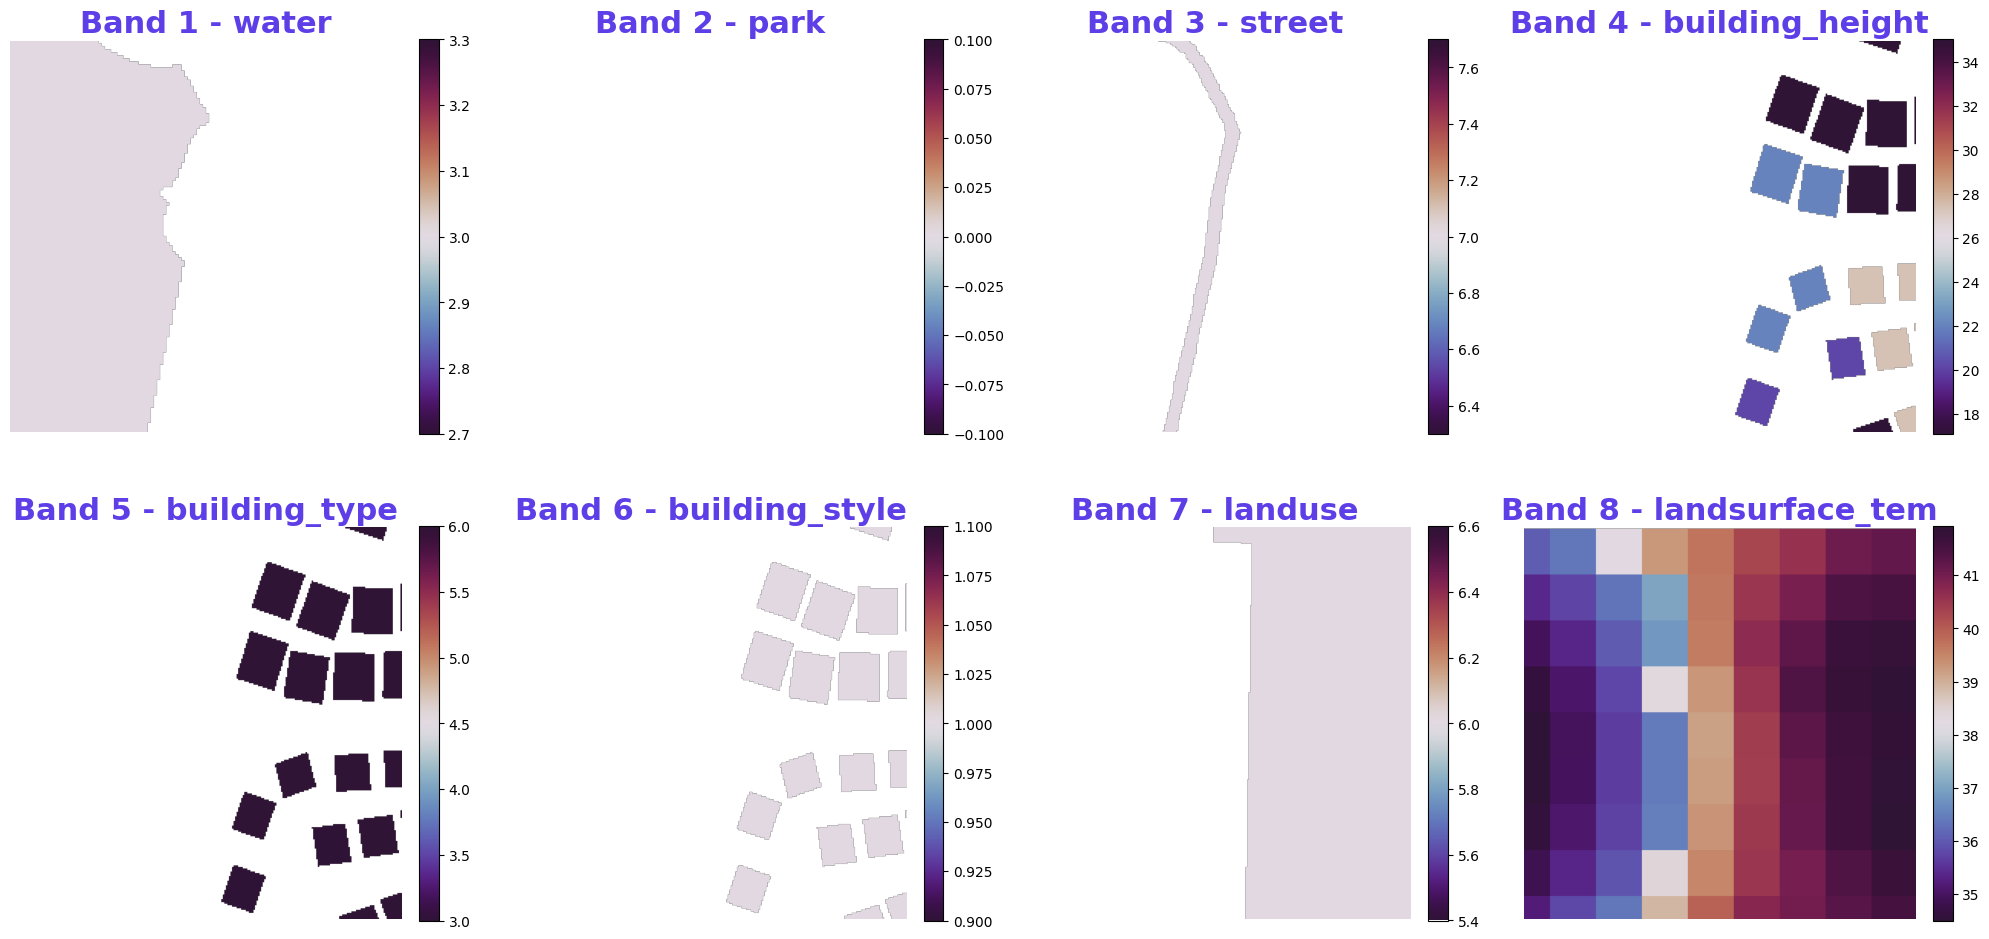

In [16]:
import rasterio
import numpy as np
import matplotlib.pyplot as plt

file_path = r"D:\shanghai workshop\raster\merged_multiband\merged_tile_192.tif"#D:\shanghai workshop\raster\merged_multiband\merged_tile_192.tif

band_names = [
    "water",
    "park",
    "street",
    "building_height",
    "building_type",
    "building_style",
    "landuse",
    "landsurface_tem"
]

with rasterio.open(file_path) as src:
    nodata = -9999
    band_count = src.count

    fig, axes = plt.subplots(2, 4, figsize=(20, 10))
    axes = axes.flatten()

    for i in range(1, band_count + 1):
        band = src.read(i)
        masked_band = np.ma.masked_equal(band, nodata)

        ax = axes[i-1]
        im = ax.imshow(masked_band, cmap="twilight_shifted")
        # magma

        # twilight_shifted
        # Purples
        ax.set_title(f"Band {i} - {band_names[i-1]}", fontsize=22, fontweight='bold', color='#5E3FE7')

        ax.axis('off')
        fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

    plt.tight_layout()
    plt.show()


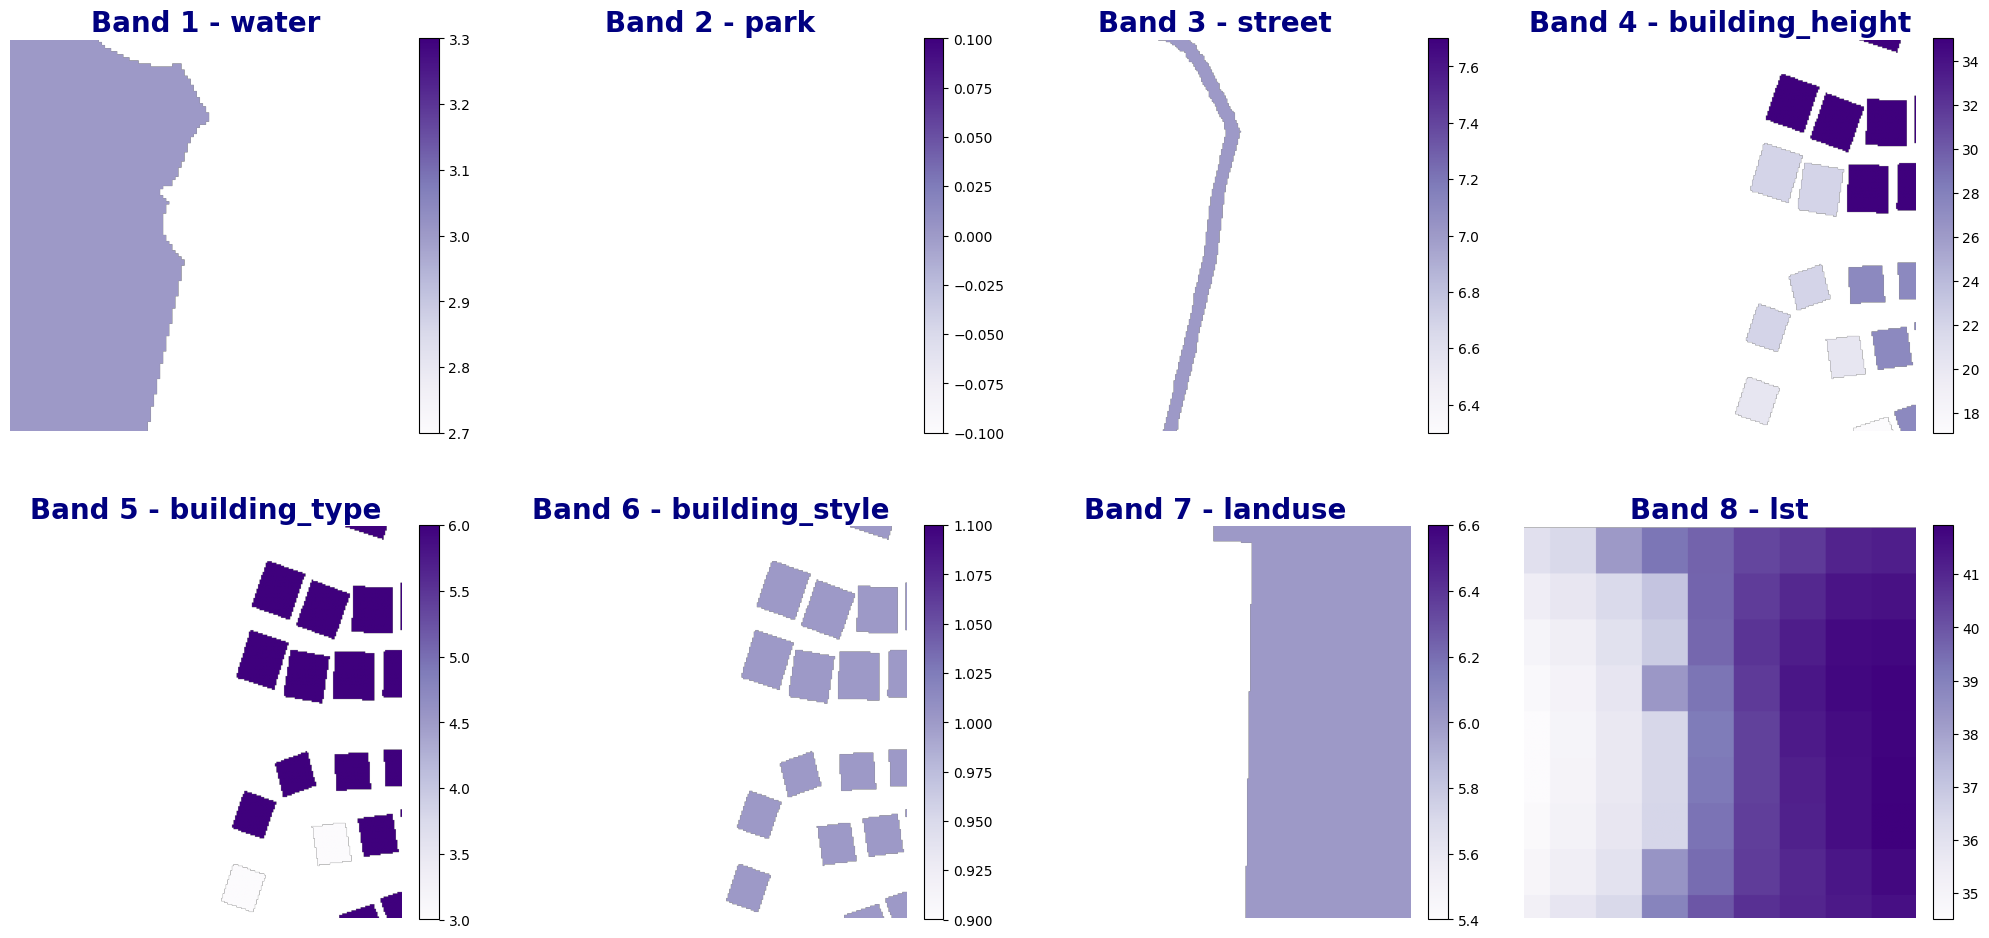

In [17]:
import rasterio
import numpy as np
import matplotlib.pyplot as plt

file_path = r"D:\shanghai workshop\raster\merged_multiband\final\multi_merged_tile_192.tif"

band_names = [
    "water",
    "park",
    "street",
    "building_height",
    "building_type",
    "building_style",
    "landuse",
    "lst"
]

with rasterio.open(file_path) as src:
    nodata = -9999
    band_count = src.count

    fig, axes = plt.subplots(2, 4, figsize=(20, 10))
    axes = axes.flatten()

    for i in range(1, band_count + 1):
        band = src.read(i)
        masked_band = np.ma.masked_equal(band, nodata)

        ax = axes[i-1]
        im = ax.imshow(masked_band, cmap="Purples")
        # magma

        # twilight_shifted
        # Purples
        ax.set_title(f"Band {i} - {band_names[i-1]}", fontsize=20, fontweight='bold', color='navy')

        ax.axis('off')
        fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

    plt.tight_layout()
    plt.show()


In [18]:
import os
import rasterio
from rasterio.merge import merge

# 参数设置
band_names = ['Band1.tif', 'Band2.tif', 'Band3.tif', 'Band4.tif','Band5.tif', 'Band6.tif', 'Band7.tif', 'Band8.tif']
tile_folder_template = r'D:\shanghai workshop\归档\T3-modified_clipped\tile_{}_{}'
output_base = r'D:\shanghai workshop\归档\T3-modified_clipped\merged_bands'

os.makedirs(output_base, exist_ok=True)

for band_name in band_names:
    tif_paths = []

    # 收集所有 tile 中该波段的路径
    for i in range(5):
        for j in range(5):
            tile_path = tile_folder_template.format(i, j)
            tif_file = os.path.join(tile_path, band_name)
            if os.path.exists(tif_file):
                tif_paths.append(tif_file)
            else:
                print(f"⚠️ 缺失: {tif_file}")

    if not tif_paths:
        print(f"❌ 没有找到任何 {band_name}，跳过该波段")
        continue

    # 打开所有文件并合并
    src_files = [rasterio.open(p) for p in tif_paths]
    mosaic, out_transform = merge(src_files)

    out_meta = src_files[0].meta.copy()
    out_meta.update({
        "height": mosaic.shape[1],
        "width": mosaic.shape[2],
        "transform": out_transform
    })

    output_path = os.path.join(output_base, f"merged_{band_name}")
    with rasterio.open(output_path, "w", **out_meta) as dest:
        dest.write(mosaic)

    for src in src_files:
        src.close()

    print(f"✅ 已拼接完成: {output_path}")


✅ 已拼接完成: D:\shanghai workshop\归档\T3-modified_clipped\merged_bands\merged_Band1.tif
✅ 已拼接完成: D:\shanghai workshop\归档\T3-modified_clipped\merged_bands\merged_Band2.tif
✅ 已拼接完成: D:\shanghai workshop\归档\T3-modified_clipped\merged_bands\merged_Band3.tif
✅ 已拼接完成: D:\shanghai workshop\归档\T3-modified_clipped\merged_bands\merged_Band4.tif
✅ 已拼接完成: D:\shanghai workshop\归档\T3-modified_clipped\merged_bands\merged_Band5.tif
✅ 已拼接完成: D:\shanghai workshop\归档\T3-modified_clipped\merged_bands\merged_Band6.tif
✅ 已拼接完成: D:\shanghai workshop\归档\T3-modified_clipped\merged_bands\merged_Band7.tif
✅ 已拼接完成: D:\shanghai workshop\归档\T3-modified_clipped\merged_bands\merged_Band8.tif


In [24]:
import rasterio
from rasterio.features import shapes
from shapely.geometry import shape
import geopandas as gpd
import numpy as np
import os

def tif_to_shapefile(tif_path, shp_path, target_value=None):
    with rasterio.open(tif_path) as src:
        band = src.read(1)
        nodata = src.nodata

        # 掩膜：提取指定值或非 nodata 区域
        if target_value is not None:
            mask = band == target_value
        else:
            mask = band != nodata if nodata is not None else np.ones_like(band, dtype=bool)

        # 栅格转矢量 polygons
        results = (
            {"geometry": shape(geom), "value": value}
            for geom, value in shapes(band, mask=mask, transform=src.transform)
        )

        # 创建 GeoDataFrame（修正版本）
        records = [(feat["geometry"], feat["value"]) for feat in results]
        gdf = gpd.GeoDataFrame(records, columns=["geometry", "value"])
        gdf.set_crs(src.crs, inplace=True)

    os.makedirs(os.path.dirname(shp_path), exist_ok=True)
    gdf.to_file(shp_path, driver="ESRI Shapefile")
    print(f"✅ 已保存至: {shp_path}")
for i in range(1, 8):
    # 示例用法
    tif_path = rf"D:\shanghai workshop\归档\T3-modified_clipped\merged_bands\merged_Band{i}.tif"
    shp_path = rf"D:\shanghai workshop\归档\T3-modified_clipped\merged_bands\merged_Band{i}.shp"

    tif_to_shapefile(tif_path, shp_path)


✅ 已保存至: D:\shanghai workshop\归档\T3-modified_clipped\merged_bands\merged_Band1.shp
✅ 已保存至: D:\shanghai workshop\归档\T3-modified_clipped\merged_bands\merged_Band2.shp
✅ 已保存至: D:\shanghai workshop\归档\T3-modified_clipped\merged_bands\merged_Band3.shp
✅ 已保存至: D:\shanghai workshop\归档\T3-modified_clipped\merged_bands\merged_Band4.shp
✅ 已保存至: D:\shanghai workshop\归档\T3-modified_clipped\merged_bands\merged_Band5.shp
✅ 已保存至: D:\shanghai workshop\归档\T3-modified_clipped\merged_bands\merged_Band6.shp
✅ 已保存至: D:\shanghai workshop\归档\T3-modified_clipped\merged_bands\merged_Band7.shp


### 单元说明：引入栅格处理库（准备后续操作）

目的：导入 `rasterio`（及后续单元可能使用的其它库）以便打开、读取或处理栅格文件。

关键点：
- 该单元仅包含导入语句，通常作为 notebook 的环境准备部分。
- 建议：在执行依赖库的单元之前先运行该单元，确保 import 不报错。